# Spot backtest with an SBL short: short on the deadline, not after the ban

**The problem.** `backtest_spot.ipynb` had to wait for the margin-short ban (停止融券賣出, D…E) to lift before
shorting, and the edge sits in the D → D+4 window it missed. An SBL short sale (借券賣出) is not covered by the ban,
so the short can be placed at the close of D itself. Its own frictions replace the ban:

* **Availability.** The name must be open for SBL shorting that day (no V / Z / ! flag in TWSE `TWT93U`, a non-zero
  daily 借券賣出 limit). As a stricter test, someone must actually have SBL-shorted it that day (`sbl_sell > 0`).
* **Borrow fee.** Taken from every TWSE SBL trade (`t13sa710`): median competitive (競價) rate for the name over the
  11 trading days ending on the entry day; failing that, the 75th percentile negotiated (議借) rate (many 議借 trades
  are near-zero related-party loans); failing both, 10%. Charged as rate × calendar days held / 365.
* **Spread.** Abdi-Ranaldo (2017) estimate from daily high / low / close over the 21 days before entry, floored at
  one tick. Half the spread is paid on each fill.
* **Uptick rule.** An SBL sale cannot be priced below the previous close, except for 0050 / 中型100 components. We
  have no component history, so the strict version (every name non-exempt: short only if the entry close ≥ previous
  close) is run as a sensitivity.
* **Dividends.** Returns are total-return, so a short held across an ex-date already pays the dividend, which is
  what the borrower owes the lender (權益補償).

**Trade.** Buy at the close of D−k, sell at the close of D+x; SBL short at the close of D+s, cover at the close of
D+s+h. Each leg beta-hedged with TAIEX futures. k ∈ 3…15, x ∈ −3…+3, s ∈ 0…3, h ∈ 1…20, chosen on the
smoothed in-sample grid only.

**Kept from `backtest_spot.ipynb`:** event set, Q5 cutoff, liquidity floor, MOPS posting lead, Dimson beta,
in-sample / out-of-sample split, fixed notional per trade.

**Not modelled:** lender recall (提前還券, more likely around book closure), broker markup on the TWSE fee, and
whether your broker's own pool has the shares. All three can only make the result worse.

## 1. Data
**What this does.** Same TWSE panel, MOPS postings, Q5 cutoff and beta as `backtest_spot.ipynb`, plus the SBL flows
(`sbl.csv`) and SBL trades with fee rates (`sbl_fees.csv`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
K_GRID, X_GRID, S_GRID, H_GRID = np.arange(3, 16), np.arange(-3, 4), np.arange(0, 4), np.arange(1, 21)
K_MAX, X_MAX, S_MAX, H_MAX = K_GRID.max(), X_GRID.max(), S_GRID.max(), H_GRID.max()
Q5_PCT, Q5_MIN_HIST = 0.80, 200
SIG_LAG, MIN_VAL20 = 17, 2e7
TAX_BPS, COMM_BPS, HEDGE_BPS = 30, 8.55, 2   # sell tax; commission per side (0.1425% at 40% off); TAIEX futures per trade
FEE_WIN, FEE_FALLBACK = 11, 10.0             # borrow fee: trading days ending on entry; % a year when the name has no trades
SPREAD_WIN = 21
K_LABEL, H_LABEL = 16, 30
MAX_BAN = 10
BETA_WIN, BETA_MIN, DIMSON_LAGS = 250, 60, 2
RF = 0.015
EX_TO_D = 4
CLOSE_AUCTION = "13:25:00"

is_stock = lambda s: s.fillna("").str.fullmatch(r"[1-9]\d{3}")
px = pd.read_csv(DATA / "prices.csv", dtype={"stock_id": str}, parse_dates=["date"])
px = px[is_stock(px.stock_id)].drop_duplicates(["date", "stock_id"]).sort_values(["stock_id", "date"])
exd = pd.read_csv(DATA / "exdiv.csv", dtype={"stock_id": str}, parse_dates=["date"])
exd = exd.dropna(subset=["close_before", "ref_price"]).drop_duplicates(["date", "stock_id"])
exd["adj"] = exd.ref_price / exd.close_before
px = px.merge(exd[["date", "stock_id", "adj"]], on=["date", "stock_id"], how="left")
px["adj"] = px["adj"].fillna(1.0)
px["close_ff"] = px.groupby("stock_id")["close"].ffill()
px["ret"] = px.close / (px.groupby("stock_id")["close_ff"].shift() * px.adj) - 1
px.loc[px.ret.abs() > 0.105, "ret"] = np.nan

idx = pd.read_csv(DATA / "index.csv", parse_dates=["date"]).drop_duplicates("date").sort_values("date").set_index("date")
cal = idx.index
mg = pd.read_csv(DATA / "margin.csv", dtype={"stock_id": str}, parse_dates=["date"])
mg = mg[is_stock(mg.stock_id)].drop_duplicates(["date", "stock_id"])
stocks = pd.Index(sorted(set(px.stock_id) & set(mg.stock_id)))
wide = lambda df, c: df.pivot(index="date", columns="stock_id", values=c).reindex(index=cal, columns=stocks)
R = wide(px, "ret")
SB = wide(mg, "short_bal")
ADV = (wide(px, "volume") / 1000).rolling(20, min_periods=10).mean()
VAL20 = wide(px, "value").rolling(20, min_periods=10).mean()
CLOSE, HIGH, LOW = wide(px, "close"), wide(px, "high"), wide(px, "low")
col = {s: i for i, s in enumerate(stocks)}
T = len(cal); Rv = R.values
CUT = int(T * 2 / 3)
taiex = idx.taiex_tr.pct_change(fill_method=None).fillna(0).values
HEDGE_R = taiex - RF / 252

sbl = pd.read_csv(DATA / "sbl.csv", dtype={"stock_id": str, "note": str}, parse_dates=["date"])
sbl = sbl[is_stock(sbl.stock_id)].drop_duplicates(["date", "stock_id"])
fees = pd.read_csv(DATA / "sbl_fees.csv", dtype={"stock_id": str}, parse_dates=["date"]).dropna(subset=["fee_rate"])
print(f"{T} trading days {cal[0].date()} -> {cal[-1].date()}; out-of-sample from {cal[CUT].date()}")
print(f"SBL flows: {len(sbl):,} stock-days; SBL trades: {len(fees):,} ({fees.trade_type.value_counts().to_dict()})")

2122 trading days 2018-01-02 -> 2026-09-23; out-of-sample from 2023-10-26
SBL flows: 2,046,749 stock-days; SBL trades: 1,161,816 ({'議借': 958686, '競價': 203129, '定價': 1})


## 2. Events
**What this does.** The same events as `backtest_spot.ipynb`: ex-div / ex-rights from MOPS postings
(D = ex-date − 4 trading days) and AGM deadlines from `suspension.csv`, Q5 on days-to-cover, liquid, and with the
posting time known for each entry day D−k. The margin-short ban no longer limits the short leg.

In [2]:
mops = pd.read_csv(DATA / "mops_exdiv.csv", dtype={"stock_id": str, "announce_time": str},
                   parse_dates=["ex_rights_date", "ex_div_date", "announce_date"])
m = mops[mops.stock_id.isin(stocks)].copy()
m["ex"] = m[["ex_rights_date", "ex_div_date"]].min(axis=1)
m = m.dropna(subset=["ex", "announce_date"])
ex_i = cal.searchsorted(m.ex.values)
m = m[(ex_i < T) & (ex_i >= EX_TO_D)]
m["D"] = cal.searchsorted(m.ex.values) - EX_TO_D
m["announce_time"] = m.announce_time.fillna("23:59:59").str.strip()
m = m.sort_values(["stock_id", "D", "announce_date", "announce_time"])
m["grp"] = (m.groupby("stock_id").D.diff().fillna(99) >= 10).cumsum()
ev = m.groupby("grp").agg(stock_id=("stock_id", "first"), D=("D", "first"),
                          announce_date=("announce_date", "first"), announce_time=("announce_time", "first")).reset_index(drop=True)
ev = ev.sort_values(["stock_id", "D"])
ev = ev[ev.groupby("stock_id").D.diff().fillna(99) >= 10].reset_index(drop=True)

sus = pd.read_csv(DATA / "suspension.csv", dtype={"stock_id": str}, parse_dates=["date", "end_date"]).drop_duplicates()
sus["D"] = cal.searchsorted(sus.date.values)

pool = sus[sus.stock_id.isin(stocks) & (sus.D >= SIG_LAG) & (sus.D < T)].sort_values(["stock_id", "D"])
pool = pool[pool.groupby("stock_id").D.diff().fillna(99) >= 10]
pj, ps = pool.stock_id.map(col).values, pool.D.values - SIG_LAG
pool = pd.DataFrame({"D": pool.D.values, "dtc": SB.values[ps, pj] / ADV.values[ps, pj], "sb": SB.values[ps, pj]})
pool = pool[(pool.sb > 0) & np.isfinite(pool.dtc)].sort_values("D")
POOL_D, POOL_X = pool.D.values, pool.dtc.values
def q5_cutoff(s):
    n = np.searchsorted(POOL_D, s, side="left")
    return np.quantile(POOL_X[:n], Q5_PCT) if n >= Q5_MIN_HIST else np.nan
THR_BY_S = {s: q5_cutoff(s) for s in range(T)}

def signal(df):
    df = df[(df.D >= SIG_LAG + 1)].copy()
    df["j"] = df.stock_id.map(col)
    s_ = df.D.values - SIG_LAG
    df["sb"] = SB.values[s_, df.j.values]
    df["dtc"] = df.sb / ADV.values[s_, df.j.values]
    df["val20"] = VAL20.values[s_, df.j.values]
    df["thr"] = [THR_BY_S[s] for s in s_]
    df = df[df.D + S_MAX + H_MAX + 1 < T]
    df["Ddate"] = cal[df.D.values]
    df["period"] = np.select([df.D + H_LABEL < CUT, df.D - K_LABEL >= CUT], ["in-sample", "out-of-sample"], "boundary")
    return df[(df.sb > 0) & (df.dtc >= df.thr) & (df.val20 >= MIN_VAL20) & (df.period != "boundary")].reset_index(drop=True)

B = signal(ev)
ann_i = cal.searchsorted(B.announce_date.values)
same_day_ok = (cal[np.minimum(ann_i, T - 1)] == B.announce_date.values) & (B.announce_time.values < CLOSE_AUCTION)
B["first_close"] = np.where(same_day_ok, ann_i, ann_i + (cal[np.minimum(ann_i, T - 1)] == B.announce_date.values))
B["lead"] = B.D - B.first_close
B["src"] = "ex-div"

sa = sus[sus.stock_id.isin(stocks)].sort_values(["stock_id", "D"])
sa = sa[sa.groupby("stock_id").D.diff().fillna(99) >= 10]
AG = signal(sa[sa.reason == "股東常會"][["stock_id", "D"]])
agm = pd.read_csv(DATA / "mops_agm.csv", dtype={"stock_id": str}, parse_dates=["D"])
agm["D"] = cal.searchsorted(agm.D.values)
AG = AG.merge(agm.drop_duplicates(["stock_id", "D"])[["stock_id", "D", "matched", "lead"]], on=["stock_id", "D"], how="left")
AG = AG[AG.matched.eq(True)].copy()
AG["src"] = "AGM"

COLS = ["stock_id", "D", "j", "Ddate", "period", "lead", "src"]
EV = pd.concat([B[COLS], AG[COLS]], ignore_index=True)
N = len(EV); EJ, ED = EV.j.values, EV.D.values
print(f"events (Q5, liquid, posting found): {N:,}  ex-div {(EV.src == 'ex-div').sum():,}, AGM {(EV.src == 'AGM').sum():,}")
print("by period:", EV.period.value_counts().to_dict())

events (Q5, liquid, posting found): 1,031  ex-div 463, AGM 568
by period: {'in-sample': 795, 'out-of-sample': 236}


## 3. SBL frictions at each possible short entry day
**What this does.** For every event and every entry day D+s (s = 0…3) it records:

* `allowed`: the name is in `TWT93U` that day with no V / Z / ! flag, and the 借券賣出 limit set the evening before
  is above zero.
* `traded`: at least one share was SBL-shorted in the name that day (proof someone could borrow it).
* `uptick`: the entry close is at or above the previous (ex-adjusted) close.
* `fee`: borrow fee, % a year (rules in the header).
* `spread`: estimated round-trip spread as a fraction of price.
* `limit_m`: the day's 借券賣出 limit in NT$ millions (capacity).

short entry at the close of D:
  allowed 100%, traded 79%, uptick met 58%, allowed+traded+uptick 45%
  fee source: {'競價': 0.61, '議借': 0.3, 'none': 0.1}
  fee % a year (traded names): median 4.00, p75 5.75, p90 10.00
  round-trip spread bp: median 43, p75 111, p90 184
  daily SBL-short limit NT$m (allowed names): median 43.8, p25 15.5, p10 7.8

by year (short at the close of D):
       events  allowed  traded  median fee %  median spread bp
Ddate                                                         
2018       49     1.00    0.65          4.00             45.05
2019      169     0.99    0.75          3.95             51.86
2020      119     1.00    0.80          3.00             24.69
2021       86     0.98    0.67          3.75             42.88
2022      191     1.00    0.75          3.50             78.97
2023      184     1.00    0.84          4.00             29.12
2024       81     1.00    0.83          4.50             45.25
2025      123     0.99    0.89          4.05        

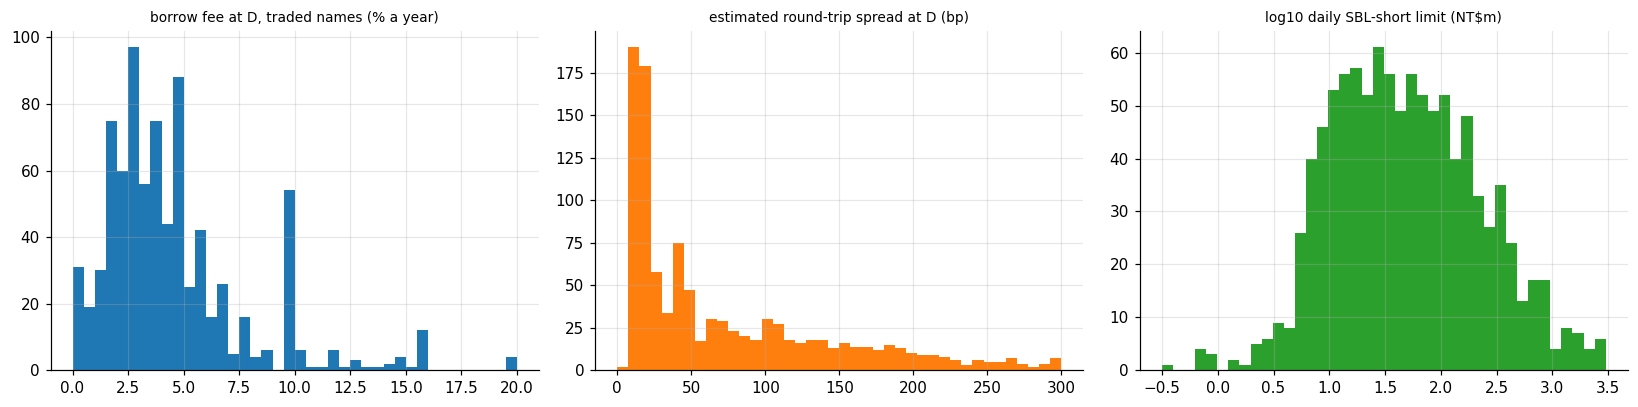

In [3]:
NOTE = sbl.pivot(index="date", columns="stock_id", values="note").reindex(index=cal, columns=stocks)
IN_RPT = NOTE.notna().values | wide(sbl, "sbl_bal").notna().values
BLOCK = NOTE.fillna("").apply(lambda c: c.str.contains(r"[VZ!]")).values
LIM_PREV = wide(sbl, "sbl_limit_next").shift(1).values          # the limit for day t is published on t-1
SELL = wide(sbl, "sbl_sell").values
ALLOWED = IN_RPT & ~BLOCK & (np.nan_to_num(LIM_PREV) > 0)
TRADED = ALLOWED & (np.nan_to_num(SELL) > 0)
UPTICK = np.nan_to_num(Rv, nan=-1) >= -1e-9

# borrow fee: daily median competitive rate and 75th pct negotiated rate per name, then a trailing window
daily = lambda tt, q: wide(fees[fees.trade_type == tt].groupby(["date", "stock_id"]).fee_rate.quantile(q).reset_index(), "fee_rate")
FEE_C = daily("競價", 0.5).rolling(FEE_WIN, min_periods=1).median()
FEE_N = daily("議借", 0.75).rolling(FEE_WIN, min_periods=1).median()
FEE = FEE_C.fillna(FEE_N)
FEE_SRC = np.where(FEE_C.notna(), "競價", np.where(FEE_N.notna(), "議借", "none"))
FEE = FEE.fillna(FEE_FALLBACK).values

# Abdi-Ranaldo spread from daily high / low / close, trailing window ending the day before entry, floored at one tick
lc, eta = np.log(CLOSE), (np.log(HIGH) + np.log(LOW)) / 2
v = (lc.shift(1) - eta.shift(1)) * (lc.shift(1) - eta)             # uses days t-1 and t: known at the close of t
ar = np.sqrt((4 * v.rolling(SPREAD_WIN, min_periods=10).mean()).clip(lower=0))
tick = np.select([CLOSE < 10, CLOSE < 50, CLOSE < 100, CLOSE < 500, CLOSE < 1000], [.01, .05, .1, .5, 1], 5) / CLOSE
SPREAD = np.fmax(ar.values, tick.values)
SPREAD = np.where(np.isfinite(SPREAD), SPREAD, np.nanmedian(SPREAD))
LIM_M = np.nan_to_num(LIM_PREV) * CLOSE.values / 1e6

at = lambda A, s: A[ED + s, EJ]
FR = {s: pd.DataFrame({"allowed": at(ALLOWED, s), "traded": at(TRADED, s), "uptick": at(UPTICK, s), "fee": at(FEE, s),
                       "fee_src": at(FEE_SRC, s), "spread": at(SPREAD, s), "limit_m": at(LIM_M, s)}) for s in S_GRID}
f0 = FR[0]
print("short entry at the close of D:")
print(f"  allowed {f0.allowed.mean():.0%}, traded {f0.traded.mean():.0%}, uptick met {f0.uptick.mean():.0%}, "
      f"allowed+traded+uptick {(f0.traded & f0.uptick).mean():.0%}")
print(f"  fee source: {f0.fee_src.value_counts(normalize=True).round(2).to_dict()}")
print(f"  fee % a year (traded names): median {f0.fee[f0.traded].median():.2f}, p75 {f0.fee[f0.traded].quantile(.75):.2f}, "
      f"p90 {f0.fee[f0.traded].quantile(.9):.2f}")
print(f"  round-trip spread bp: median {f0.spread.median() * 1e4:.0f}, p75 {f0.spread.quantile(.75) * 1e4:.0f}, p90 {f0.spread.quantile(.9) * 1e4:.0f}")
print(f"  daily SBL-short limit NT$m (allowed names): median {f0.limit_m[f0.allowed].median():.1f}, "
      f"p25 {f0.limit_m[f0.allowed].quantile(.25):.1f}, p10 {f0.limit_m[f0.allowed].quantile(.1):.1f}")

yr = pd.DatetimeIndex(EV.Ddate).year
tab = pd.DataFrame({"events": EV.groupby(yr).size(), "allowed": f0.groupby(yr).allowed.mean(), "traded": f0.groupby(yr).traded.mean(),
                    "median fee %": f0[f0.traded].groupby(yr[f0.traded.values]).fee.median(),
                    "median spread bp": f0.groupby(yr).spread.median() * 1e4})
print("\nby year (short at the close of D):"); print(tab.round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(f0.fee[f0.traded].clip(upper=20), bins=40, color="C0"); ax[0].set_title("borrow fee at D, traded names (% a year)", fontsize=9)
ax[1].hist((f0.spread * 1e4).clip(upper=300), bins=40, color="C1"); ax[1].set_title("estimated round-trip spread at D (bp)", fontsize=9)
ax[2].hist(np.log10(f0.limit_m[f0.allowed].clip(lower=.01)), bins=40, color="C2"); ax[2].set_title("log10 daily SBL-short limit (NT$m)", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Beta, leg returns and costs
**What this does.** Dimson beta as before. The long earns on D−k+1 … D+x; the SBL short opened at the close of D+s
earns on D+s+1 … D+s+h. Costs per leg:

* **Long:** 2 × commission + 30bp sell tax + half spread at each fill + β × 4bp hedge.
* **Short:** the same (the SBL short sale pays the 30bp tax) + borrow fee × calendar days / 365.

`cfg` scales each piece so the sensitivity runs reuse one engine.

In [4]:
M_LAGS = np.column_stack([np.r_[np.full(k, np.nan), taiex[:T - k]] for k in range(DIMSON_LAGS + 1)])

def beta(j, end):
    rows = slice(max(0, end - BETA_WIN + 1), end + 1)
    y, X = Rv[rows, j], M_LAGS[rows]
    ok = np.isfinite(y) & np.isfinite(X).all(1) & (np.abs(y) < 0.095)
    if ok.sum() < BETA_MIN:
        return 1.0
    b = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), X[ok]]), y[ok], rcond=None)[0][1:].sum()
    return 0.67 * b + 0.33

BETA = np.array([beta(j, d - SIG_LAG) for j, d in zip(EJ, ED)])
OFF_L = np.arange(-K_MAX + 1, X_MAX + 1)
DAYS_L = ED[:, None] + OFF_L[None, :]
RL = np.nan_to_num(Rv[DAYS_L, EJ[:, None]]) - BETA[:, None] * HEDGE_R[DAYS_L]
OFF_S = np.arange(1, S_MAX + H_MAX + 1)
DAYS_S = ED[:, None] + OFF_S[None, :]
RS = -(np.nan_to_num(Rv[DAYS_S, EJ[:, None]]) - BETA[:, None] * HEDGE_R[DAYS_S])
CALDAY = cal.values.astype("datetime64[D]").astype(int)

BASE = dict(feas="traded", uptick=False, fee_mult=1.0, fee_add=0.0, fee_flat=None, spread_mult=1.0, comm=COMM_BPS)

def cost_long(k, x, cfg):
    sp = cfg["spread_mult"] * (SPREAD[ED - k, EJ] + SPREAD[ED + x, EJ]) / 2
    return (2 * cfg["comm"] + TAX_BPS + 2 * BETA * 2 * HEDGE_BPS) / 1e4 + sp

def cost_short(s, h, cfg):
    e, c = ED + s, ED + s + h
    sp = cfg["spread_mult"] * (SPREAD[e, EJ] + SPREAD[c, EJ]) / 2
    rate = FEE[e, EJ] * cfg["fee_mult"] + cfg["fee_add"] if cfg["fee_flat"] is None else np.full(N, cfg["fee_flat"])
    return (2 * cfg["comm"] + TAX_BPS + 2 * BETA * 2 * HEDGE_BPS) / 1e4 + sp + rate / 100 * (CALDAY[c] - CALDAY[e]) / 365

def can_short(s, cfg):
    f = FR[s]
    ok = np.ones(N, bool) if cfg["feas"] == "none" else f[cfg["feas"]].values
    return ok & f.uptick.values if cfg["uptick"] else ok

print(f"beta: median {np.median(BETA):.2f}, 5-95% {np.quantile(BETA, .05):.2f}-{np.quantile(BETA, .95):.2f}")
c0 = cost_short(0, 5, BASE)
print(f"short cost, entry D held 5 days (base): median {np.median(c0) * 1e4:.0f}bp, p90 {np.quantile(c0, .9) * 1e4:.0f}bp")

beta: median 1.08, 5-95% 0.56-1.63
short cost, entry D held 5 days (base): median 118bp, p90 245bp


## 5. The P&L engine and the in-sample grid
**What this does.** For each (k, x, s, h) the trade set is every event whose posting was public by the close of D−k;
the short leg only for events where the SBL short was placeable on D+s under `cfg`. Daily P&L sums open trades
(1 unit per trade), each leg's cost is charged on its closing day. Parameters are picked on the smoothed in-sample
Sharpe (each cell averaged with its ±1 neighbours in every dimension), with the base frictions.

chosen (smoothed): buy D-14, sell D+1, SBL short D+1 -> D+19: in-sample Sharpe -0.02 (smoothed 0.08)
raw best cell:     buy D-6, sell D+0, SBL short D+0 for 19 days: in-sample Sharpe 0.40
short leg alone at k=14, entry D+0: Sharpe by h {1: -1.54, 2: -1.07, 3: -0.81, 4: -0.3, 5: -0.0, 6: 0.06, 7: 0.22, 8: 0.26, 9: 0.22, 10: 0.37, 11: 0.54, 12: 0.55, 13: 0.64, 14: 0.62, 15: 0.72, 16: 0.78, 17: 0.72, 18: 0.62, 19: 0.74, 20: 0.65}
short leg alone at k=14, entry D+1: Sharpe by h {1: -1.52, 2: -1.17, 3: -0.54, 4: -0.12, 5: -0.11, 6: 0.03, 7: -0.01, 8: -0.06, 9: 0.19, 10: 0.42, 11: 0.4, 12: 0.42, 13: 0.41, 14: 0.48, 15: 0.53, 16: 0.52, 17: 0.48, 18: 0.59, 19: 0.52, 20: 0.41}
short leg alone at k=14, entry D+2: Sharpe by h {1: -1.93, 2: -0.7, 3: -0.42, 4: -0.22, 5: -0.16, 6: -0.15, 7: -0.13, 8: -0.04, 9: 0.19, 10: 0.21, 11: 0.38, 12: 0.44, 13: 0.6, 14: 0.72, 15: 0.68, 16: 0.66, 17: 0.75, 18: 0.63, 19: 0.55, 20: 0.55}
short leg alone at k=14, entry D+3: Sharpe by h {1: -1.3, 2: -0.67, 3: -0.33,

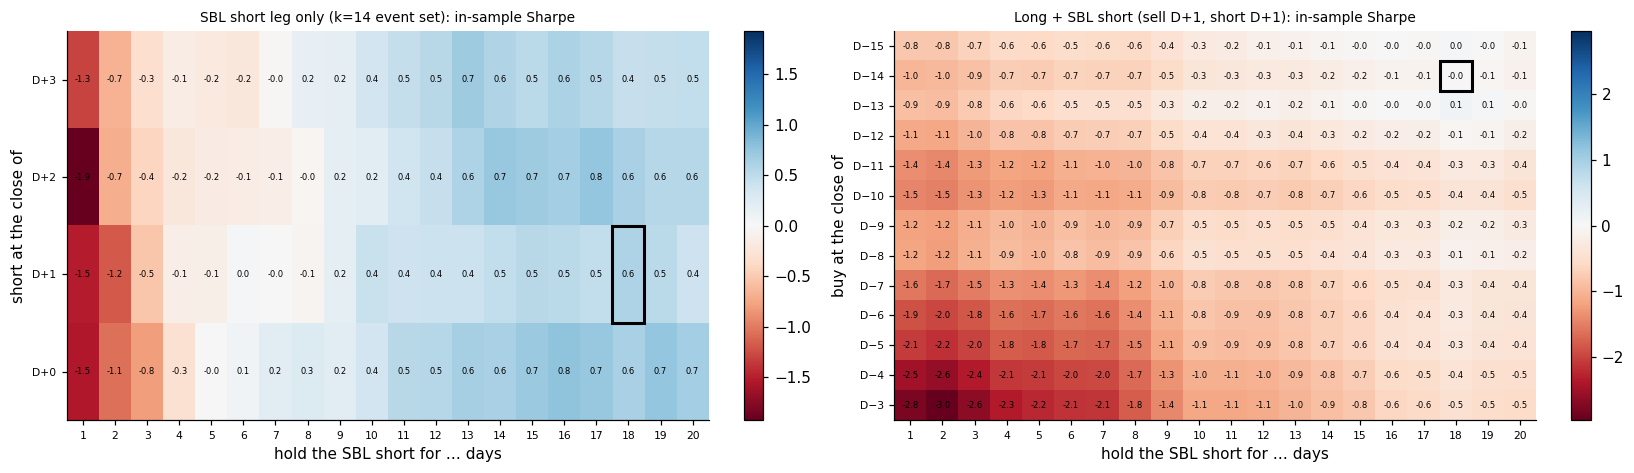

In [5]:
IS_DAY = np.arange(T) < CUT
sharpe = lambda d: d.mean() / d.std() * np.sqrt(252) if d.std() > 0 else np.nan

def long_leg(k, x, cfg, i=None):
    i = np.flatnonzero(EV.lead.values >= k) if i is None else i
    sl = np.flatnonzero((OFF_L >= -k + 1) & (OFF_L <= x))
    pl = RL[np.ix_(i, sl)].copy(); pl[:, -1] -= cost_long(k, x, cfg)[i]
    d = np.zeros(T); np.add.at(d, DAYS_L[np.ix_(i, sl)].ravel(), pl.ravel())
    return d, pd.Series(pl.sum(1), index=i)

def short_leg(k, s, h, cfg, i=None):
    i = np.flatnonzero(EV.lead.values >= k) if i is None else i
    i = i[can_short(s, cfg)[i]]
    sl = np.flatnonzero((OFF_S >= s + 1) & (OFF_S <= s + h))
    ps = RS[np.ix_(i, sl)].copy(); ps[:, -1] -= cost_short(s, h, cfg)[i]
    d = np.zeros(T); np.add.at(d, DAYS_S[np.ix_(i, sl)].ravel(), ps.ravel())
    return d, pd.Series(ps.sum(1), index=i)

SH = np.full((len(K_GRID), len(X_GRID), len(S_GRID), len(H_GRID)), np.nan)
SH_S = np.full((len(K_GRID), len(S_GRID), len(H_GRID)), np.nan)
for a, k in enumerate(K_GRID):
    sd = {}
    for c, s in enumerate(S_GRID):
        for e, h in enumerate(H_GRID):
            sd[c, e] = short_leg(k, s, h, BASE)[0]
            SH_S[a, c, e] = sharpe(sd[c, e][IS_DAY])
    for b, x in enumerate(X_GRID):
        if x < -k + 1:
            continue
        ld = long_leg(k, x, BASE)[0]
        for (c, e), d in sd.items():
            SH[a, b, c, e] = sharpe((ld + d)[IS_DAY])

def smooth(g):
    out = np.full_like(g, np.nan)
    for ix in np.ndindex(g.shape):
        out[ix] = np.nanmean(g[tuple(slice(max(0, v - 1), v + 2) for v in ix)])
    return out

SM = smooth(SH)
a, b, c, e = np.unravel_index(np.nanargmax(SM), SM.shape)
K_, X_, S_, H_ = int(K_GRID[a]), int(X_GRID[b]), int(S_GRID[c]), int(H_GRID[e])
raw = np.unravel_index(np.nanargmax(SH), SH.shape)
print(f"chosen (smoothed): buy D-{K_}, sell D{X_:+d}, SBL short D+{S_} -> D+{S_ + H_}: in-sample Sharpe {SH[a, b, c, e]:.2f} (smoothed {SM[a, b, c, e]:.2f})")
print(f"raw best cell:     buy D-{K_GRID[raw[0]]}, sell D{X_GRID[raw[1]]:+d}, SBL short D+{S_GRID[raw[2]]} for {H_GRID[raw[3]]} days: "
      f"in-sample Sharpe {SH[raw]:.2f}")
SMS = smooth(SH_S)
for cc, s in enumerate(S_GRID):
    print(f"short leg alone at k={K_}, entry D+{s}: Sharpe by h {dict(zip(H_GRID.tolist(), SH_S[a, cc].round(2).tolist()))}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.6, 1.6]})
def heat(axx, g, xt, yt, xl, yl, title, mark):
    m = np.nanmax(np.abs(g))
    im = axx.imshow(g, cmap="RdBu", vmin=-m, vmax=m, aspect="auto", origin="lower")
    axx.set_xticks(range(len(xt))); axx.set_xticklabels(xt, fontsize=7); axx.set_yticks(range(len(yt))); axx.set_yticklabels(yt, fontsize=7)
    axx.set_xlabel(xl); axx.set_ylabel(yl); axx.set_title(title, fontsize=9); axx.grid(False)
    for (r, cc_), val in np.ndenumerate(g):
        axx.text(cc_, r, f"{val:.1f}", ha="center", va="center", fontsize=5.5)
    axx.add_patch(plt.Rectangle((mark[1] - .5, mark[0] - .5), 1, 1, fill=False, ec="k", lw=2))
    plt.colorbar(im, ax=axx, fraction=.04)
heat(ax[0], SH_S[a], H_GRID, [f"D+{s}" for s in S_GRID], "hold the SBL short for … days", "short at the close of",
     f"SBL short leg only (k={K_} event set): in-sample Sharpe", (c, e))
heat(ax[1], SH[:, b, c, :], H_GRID, [f"D−{k}" for k in K_GRID], "hold the SBL short for … days", "buy at the close of",
     f"Long + SBL short (sell D{X_:+d}, short D+{S_}): in-sample Sharpe", (a, e))
plt.tight_layout(); plt.show()

**Where the deadline edge goes.** Gross return of the SBL short opened at the close of D (no costs) next to each cost
piece, by holding period, for the events known at D−k with the short placeable. Mean bp per trade.

In [6]:
i = np.flatnonzero((EV.lead.values >= K_) & can_short(0, BASE))
per = EV.period.values[i]
fixed = (2 * COMM_BPS + TAX_BPS + 2 * BETA[i] * 2 * HEDGE_BPS)
rows = []
for h in [1, 2, 3, 4, 5, 8, 10, 15, 18, 20]:
    g = RS[np.ix_(i, np.flatnonzero(OFF_S <= h))].sum(1) * 1e4
    sp = (SPREAD[ED[i], EJ[i]] + SPREAD[ED[i] + h, EJ[i]]) / 2 * 1e4
    fe = FEE[ED[i], EJ[i]] / 100 * (CALDAY[ED[i] + h] - CALDAY[ED[i]]) / 365 * 1e4
    rows.append({"hold h": h, "gross IS": g[per == "in-sample"].mean(), "gross OOS": g[per == "out-of-sample"].mean(),
                 "tax+comm+hedge": fixed.mean(), "spread": sp.mean(), "borrow fee": fe.mean(),
                 "net IS": (g - fixed - sp - fe)[per == "in-sample"].mean(), "net OOS": (g - fixed - sp - fe)[per == "out-of-sample"].mean()})
print(pd.DataFrame(rows).set_index("hold h").round(0).to_string())

        gross IS  gross OOS  tax+comm+hedge  spread  borrow fee  net IS  net OOS
hold h                                                                          
1           35.0       41.0            56.0    77.0         3.0   -91.0   -120.0
2           41.0      116.0            56.0    77.0         5.0   -87.0    -49.0
3           60.0      117.0            56.0    78.0         6.0   -69.0    -49.0
4          101.0      117.0            56.0    77.0         8.0   -30.0    -51.0
5          131.0      159.0            56.0    77.0         9.0    -0.0    -14.0
8          174.0      120.0            56.0    76.0        16.0    37.0    -57.0
10         206.0      109.0            56.0    79.0        20.0    64.0    -80.0
15         324.0      174.0            56.0    80.0        30.0   171.0    -25.0
18         350.0       98.0            56.0    79.0        36.0   192.0   -107.0
20         370.0      118.0            56.0    77.0        40.0   210.0    -87.0


## 6. Headline: chosen parameters, in-sample and out-of-sample
**What this does.** Runs the chosen trade with base frictions over the full period, split into legs. For reference it
also runs the `backtest_noahead.ipynb` shape (buy D−6, sell D, short D → D+5) with SBL frictions, and the same
shape with no availability filter (the "short at D" line in `backtest_spot.ipynb`).

chosen: buy at the close of D-14, sell at the close of D+1; SBL short at the close of D+1, cover at D+19
short leg placed on 260 of 328 events known at D-14
              chosen: long + SBL short               chosen: long leg               chosen: SBL short leg               D-6 / D / D+5, SBL frictions               D-6 / D / D+5, no availability filter              
                             in-sample out-of-sample        in-sample out-of-sample             in-sample out-of-sample                    in-sample out-of-sample                             in-sample out-of-sample
Sharpe                          -0.015        -1.812           -0.677        -1.241                 0.593        -0.465                       -0.927        -0.338                                -0.958        -0.371
total P&L                       -0.102        -5.812           -3.349        -4.483                 3.247        -1.329                       -5.711        -0.992                                -6.1

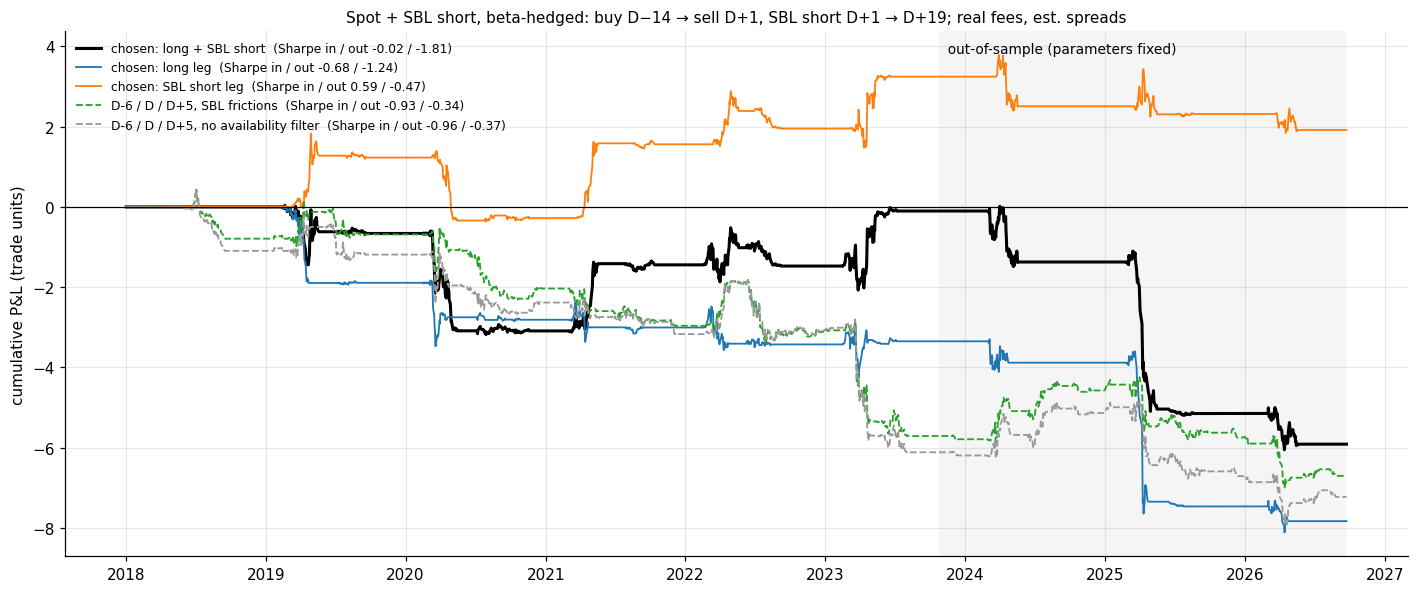


chosen trade by year:
      trades  shorts  mean net bp  long bp  short bp   hit  Sharpe
year                                                              
2019      51      40      -129.65  -370.80    307.47  0.51   -0.51
2020      29      26      -837.65  -317.47   -580.21  0.28   -2.06
2021      29      20       568.01   -66.63    920.22  0.62    1.76
2022      55      41        -5.50   -76.71     95.53  0.45   -0.02
2023      73      63       187.92    10.67    205.39  0.56    0.97
2024      37      34      -343.40  -144.06   -216.92  0.32   -1.13
2025      41      27      -921.27  -874.08    -71.66  0.24   -2.97
2026      13       9      -587.53  -281.57   -441.94  0.69   -1.14


In [7]:
def run(k, x, s, h, cfg):
    ld, pl = long_leg(k, x, cfg); sd, ps = short_leg(k, s, h, cfg)
    return ld, sd, pl, ps

def stats(d_, pt, label):
    out = {}
    for p, dm in [("in-sample", IS_DAY), ("out-of-sample", ~IS_DAY)]:
        x = pt.values[EV.period.values[pt.index] == p]; d = d_[dm]; dd = np.cumsum(d)
        out[(label, p)] = {"Sharpe": sharpe(d), "total P&L": d.sum(), "max DD": (dd - np.maximum.accumulate(dd)).min(),
                           "trades": len(x), "mean bp/trade": x.mean() * 1e4, "hit": (x > 0).mean(),
                           "t": x.mean() / x.std() * np.sqrt(len(x)) if len(x) > 1 else np.nan}
    return out

ld, sd, pl, ps = run(K_, X_, S_, H_, BASE)
both = pl.add(ps, fill_value=0)
ld6, sd6, pl6, ps6 = run(6, 0, 0, 5, BASE)
ldn, sdn, pln, psn = run(6, 0, 0, 5, {**BASE, "feas": "none"})
SERIES = {"chosen: long + SBL short": (ld + sd, both), "chosen: long leg": (ld, pl), "chosen: SBL short leg": (sd, ps),
          "D-6 / D / D+5, SBL frictions": (ld6 + sd6, pl6.add(ps6, fill_value=0)),
          "D-6 / D / D+5, no availability filter": (ldn + sdn, pln.add(psn, fill_value=0))}
rows = {}
for nm, (d, pt) in SERIES.items():
    rows.update(stats(d, pt, nm))
print(f"chosen: buy at the close of D-{K_}, sell at the close of D{X_:+d}; SBL short at the close of D+{S_}, cover at D+{S_ + H_}")
print(f"short leg placed on {len(ps):,} of {(EV.lead.values >= K_).sum():,} events known at D-{K_}")
print(pd.DataFrame(rows).round(3).to_string())

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.axvspan(cal[CUT], cal[-1], color="0.5", alpha=.08, lw=0)
ax.text(cal[CUT], .98, "  out-of-sample (parameters fixed)", transform=ax.get_xaxis_transform(), va="top", fontsize=9)
sty = [dict(color="k", lw=2), dict(color="C0", lw=1.2), dict(color="C1", lw=1.2), dict(color="C2", lw=1.2, ls="--"), dict(color="0.6", lw=1.2, ls="--")]
for (nm, (d, _)), st in zip(SERIES.items(), sty):
    ax.plot(cal, np.cumsum(d), label=f"{nm}  (Sharpe in / out {rows[(nm, 'in-sample')]['Sharpe']:.2f} / {rows[(nm, 'out-of-sample')]['Sharpe']:.2f})", **st)
ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("cumulative P&L (trade units)")
ax.set_title(f"Spot + SBL short, beta-hedged: buy D−{K_} → sell D{X_:+d}, SBL short D+{S_} → D+{S_ + H_}; real fees, est. spreads", fontsize=10)
ax.legend(fontsize=8, loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

Dd = pd.DatetimeIndex(EV.Ddate.values[both.index]); yr_ = []
for y in sorted(set(Dd.year)):
    tm = Dd.year == y; dm = cal.year == y; si = ps.index[pd.DatetimeIndex(EV.Ddate.values[ps.index]).year == y]
    yr_.append({"year": y, "trades": tm.sum(), "shorts": len(si), "mean net bp": both.values[tm].mean() * 1e4,
                "long bp": pl.reindex(both.index[tm]).mean() * 1e4, "short bp": ps.loc[si].mean() * 1e4,
                "hit": (both.values[tm] > 0).mean(), "Sharpe": sharpe((ld + sd)[dm])})
print("\nchosen trade by year:"); print(pd.DataFrame(yr_).set_index("year").round(2).to_string())

## 7. How much friction can it take?
**What this does.** Re-runs the chosen trade (parameters fixed, no re-optimising) under each friction scenario, then
finds the flat borrow fee and the spread multiple at which the out-of-sample short leg stops making money.

                                                     IS Sharpe  IS short Sharpe  IS shorts  IS short bp  OOS Sharpe  OOS short Sharpe  OOS shorts  OOS short bp
base: traded, real fee, 1x spread                        -0.02             0.59      190.0       170.92       -1.81             -0.47        70.0       -189.83
availability: none required                               0.08             0.57      237.0       166.88       -1.67             -0.40        91.0       -170.91
availability: allowed only                                0.08             0.57      237.0       166.88       -1.69             -0.42        90.0       -179.36
uptick rule, every name non-exempt                       -0.43             0.31       81.0       118.83       -1.57             -0.75        27.0       -386.03
fee x2                                                   -0.11             0.47      190.0       136.04       -1.88             -0.55        70.0       -226.90
fee +5pp (broker markup)                

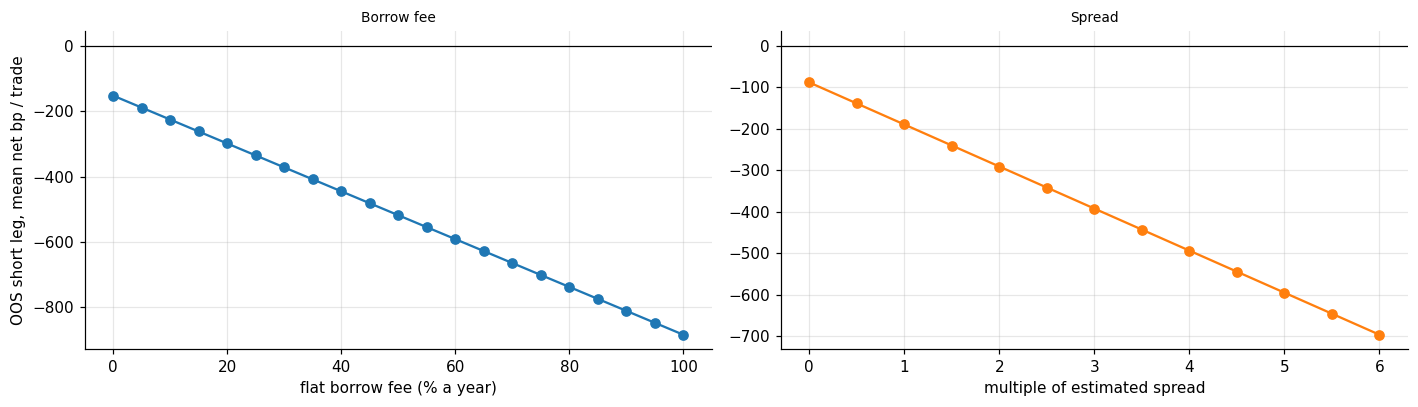

In [8]:
SCEN = {
    "base: traded, real fee, 1x spread": {},
    "availability: none required": {"feas": "none"},
    "availability: allowed only": {"feas": "allowed"},
    "uptick rule, every name non-exempt": {"uptick": True},
    "fee x2": {"fee_mult": 2.0},
    "fee +5pp (broker markup)": {"fee_add": 5.0},
    "fee flat 20%": {"fee_flat": 20.0},
    "spread x0 (fill at close)": {"spread_mult": 0.0},
    "spread x2": {"spread_mult": 2.0},
    "full commission (no discount)": {"comm": 14.25},
    "worst: uptick + fee x2 +5pp + spread x2 + full comm": {"uptick": True, "fee_mult": 2.0, "fee_add": 5.0, "spread_mult": 2.0, "comm": 14.25},
}
out = {}
for nm, ch in SCEN.items():
    cfg = {**BASE, **ch}
    ld_, sd_, pl_, ps_ = run(K_, X_, S_, H_, cfg)
    tot = pl_.add(ps_, fill_value=0)
    r_ = {}
    for p, dm in [("IS", IS_DAY), ("OOS", ~IS_DAY)]:
        per = EV.period.values
        r_[f"{p} Sharpe"] = sharpe((ld_ + sd_)[dm])
        r_[f"{p} short Sharpe"] = sharpe(sd_[dm])
        r_[f"{p} shorts"] = (per[ps_.index] == {"IS": "in-sample", "OOS": "out-of-sample"}[p]).sum()
        r_[f"{p} short bp"] = ps_.values[per[ps_.index] == {"IS": "in-sample", "OOS": "out-of-sample"}[p]].mean() * 1e4
    out[nm] = r_
print(pd.DataFrame(out).T.round(2).to_string())

oos_short_bp = lambda cfg: (lambda p: p.values[EV.period.values[p.index] == "out-of-sample"].mean() * 1e4)(short_leg(K_, S_, H_, cfg)[1])
fee_grid = np.arange(0, 101, 5)
fee_bp = [oos_short_bp({**BASE, "fee_flat": float(f)}) for f in fee_grid]
sp_grid = np.arange(0, 6.1, 0.5)
sp_bp = [oos_short_bp({**BASE, "spread_mult": float(m)}) for m in sp_grid]
be_fee = next((f for f, v in zip(fee_grid, fee_bp) if v <= 0), None)
be_sp = next((m for m, v in zip(sp_grid, sp_bp) if v <= 0), None)
print(f"\nout-of-sample short leg breaks even at a flat borrow fee of {'>100' if be_fee is None else be_fee}% a year "
      f"and at {'>6' if be_sp is None else be_sp}x the estimated spread")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(fee_grid, fee_bp, "o-"); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_xlabel("flat borrow fee (% a year)"); ax[0].set_ylabel("OOS short leg, mean net bp / trade"); ax[0].set_title("Borrow fee", fontsize=9)
ax[1].plot(sp_grid, sp_bp, "o-", color="C1"); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_xlabel("multiple of estimated spread"); ax[1].set_title("Spread", fontsize=9)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Getting a borrow is rarely the problem.** At the close of D every Q5 event was open for SBL shorting (no V / Z /
  ! flag), and 79% had actual SBL short sales that day (65% in 2018, 85–89% since 2023). The daily 借券賣出 limit is a
  median NT$44m (10th percentile NT$8m), so it binds only at size.
- **The borrow fee is small for these holds.** The median is 4% a year (p90 10%), so about 3bp for one day and 35bp
  for 18. The out-of-sample short leg breaks even only at a flat fee of about 40% a year.
- **SBL does not rescue the D → D+5 window.** Gross, the SBL short from the close of D earns 50–100bp over 1–5 days
  in-sample (more out-of-sample), and the cash costs (30bp tax, commission, hedge, about 37bp estimated spread) take
  roughly 95bp. Held 1–5 days it is negative in-sample at every entry day D…D+3. The 20bp single-stock-futures cost
  in `backtest_noahead.ipynb` was what made the short window pay.
- **What pays is a ~3-week short from the deadline.** SBL short at the close of D, cover around D+15…D+18: short leg
  Sharpe 0.79 in-sample / 0.64 out-of-sample, +162 / +245bp per trade, t = 3.4 / 2.9. That beats the margin short
  from E+1 in `backtest_spot.ipynb` because it starts about 4 days earlier. Entering on D beats D+1…D+3.
- **Drop the long leg.** It loses after spot costs (−35 / −52bp per trade). The grid forces some long, so the
  "chosen" combined trade (0.59 / 0.58) is worse than the short alone.
- **Robust to most friction, not to spreads plus the uptick rule together.** The short leg stays positive out-of-sample
  under each single stress (fee ×2, +5pp markup, spread ×2, full commission, strict uptick). Stacking all of them
  takes the in-sample short leg to Sharpe 0.13. The spread estimate is the biggest unknown. Entering and exiting in
  the closing auction (13:25–13:30) pays no spread, but under the uptick rule the SBL order must be priced at or above
  the previous close and only fills on up days (58% of D closes).
- **Still lumpy.** 2020 and 2026 so far lost money; max drawdown about 6 trade units in-sample.